# Обзор и описание данных

Ссылка для скачивания датасета: https://drive.google.com/file/d/1pHd4lhIWi-PyCjYUPky6sIT8qBPsAZts/view?usp=sharing

In [ ]:
import gdown

!gdown --id 1pHd4lhIWi-PyCjYUPky6sIT8qBPsAZts

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1pHd4lhIWi-PyCjYUPky6sIT8qBPsAZts
To: /content/coffee_shop_hard.csv
100% 6.36M/6.36M [00:00<00:00, 50.7MB/s]


In [ ]:
import pandas as pd

dataset = pd.read_csv('/content/coffee_shop_hard.csv')

dataset.head(3)

,transaction_id,quantity,unit_price,product_info,store_info,customer_info
0,0,1,162.5,"{""product_id"":52,""product_name"":""Traditional B...","{""sales_outlet_id"":3,""store_city"":""Санкт-Петер...","{""customer_id"":558,""birthdate"":""1983-02-25"",""g..."
1,1,2,227.5,"{""product_id"":27,""product_name"":""Brazilian Lg""...","{""sales_outlet_id"":3,""store_city"":""Санкт-Петер...","{""customer_id"":781,""birthdate"":""1991-07-29"",""g..."
2,2,2,162.5,"{""product_id"":46,""product_name"":""Serenity Gree...","{""sales_outlet_id"":3,""store_city"":""Санкт-Петер...","{""customer_id"":788,""birthdate"":""1995-02-23"",""g..."


In [ ]:
df  = dataset.copy()

In [ ]:
# Посмотрим размер датасета

df.shape

(24909, 6)

In [ ]:
# Посмотрим информацию о пропусках и типах данных

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24909 entries, 0 to 24908
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  24909 non-null  int64  
 1   quantity        24909 non-null  int64  
 2   unit_price      24909 non-null  float64
 3   product_info    24909 non-null  object 
 4   store_info      24909 non-null  object 
 5   customer_info   24909 non-null  object 
dtypes: float64(1), int64(2), object(3)
memory usage: 1.1+ MB


In [ ]:
# Посмотрим типы данных

df.dtypes

,0
transaction_id,int64
quantity,int64
unit_price,float64
product_info,object
store_info,object
customer_info,object


In [ ]:
# Посмотрим какие колонки содержит датасет

df.columns

Index(['transaction_id', 'quantity', 'unit_price', 'product_info',
       'store_info', 'customer_info'],
      dtype='object')

In [ ]:
 # Посмотрим как выглядят столбцы с вложенными значениями типа json

df['product_info'][0]

'{"product_id":52,"product_name":"Traditional Blend Chai Rg","product_category":"Tea"}'

In [ ]:
df['store_info'][24000]

'{"sales_outlet_id":8,"store_city":"Moscow"}'

In [ ]:
df['customer_info'][0]

'{"customer_id":558,"birthdate":"1983-02-25","gender":"женский"}'

In [ ]:
# Проверим на наличие дубликатов

dataset.duplicated().sum()

np.int64(57)

In [ ]:
# Проверим на наличие пропусков

df.isna().sum()

,0
transaction_id,0
quantity,0
unit_price,0
product_info,0
store_info,0
customer_info,0


## Начальное описание датасета

- Датасет содержит информацию о продажах в кофейнях.

- Датасет содержит 6 столбцов и 24.909 строк.

- Датасет содержит 3 колонки с вложенными объектами типа `json`.

- Датасет содержит 2 колонки с целочисленным типом данных `int64` и одну колонку с вещественным типом данных `float64`.

- Датасет НЕ содержит пустых значений. Однако, во вложенных объектах могут быть пропуски значений в парах "ключ":"значение".

- Датасет содержит 57 дубликатов.

**Описание признаков в датасете**:

1. **transaction_id**
* Уникальный идентификатор транзакции
* Тип данных: числовой
* Назначение: отслеживание каждой продажи

2. **quantity**
* Количество купленных единиц товара
* Тип данных: числовой
* Диапазон: от 1 до 2 единиц

3. **unit_price**
* Цена за единицу товара
* Тип данных: числовой
* Диапазон: от 130 до 308.75

4. **product_info**
* Вложенный объект с информацией о продукте
* Содержит:
  * product_id (идентификатор продукта)
  * product_name (название продукта)
  * product_category (категория продукта: Coffee, Tea, Drinking Chocolate, Bakery)

5. **store_info**
* Информация о магазине
* Содержит:
  * sales_outlet_id (идентификатор точки продаж)
  * store_city (город, где находится точка)

6. **customer_info**
* Информация о клиенте
* Содержит:
  * customer_id (идентификатор клиента)
  * birthdate (дата рождения)
  * gender (пол: мужской, женский, не указан)


## Проблемы датасета

- Наличие признаков, не представляющих ценности в рамках кейса (`'transaction_id', 'customer_id'`)

* Вложенные JSON-объекты в столбцах `product_info, store_info, customer_info` требуют дополнительной обработки

* Неполные данные о клиентах, есть пропуски ("не указан") по ключу `'gender'`

- Наличие закодированных значений точек (3, 5, 8), нужно будет узнавать, что это за точка, где она находится

* Неравномерное распределение категорий товаров:
  * Преобладание категории `Coffee`
  * Меньшее количество записей по `Drinking Chocolate и Bakery` и других

- Только даты рождения клиентов, нужно высчитывать возраст

- Наличие выбросов в столбцах `unit_price`, `total`

- Различия в форматах записи названий продуктов

- Непонятно, что обозначают сокращения в названиях продуктов типа "Lg. Sm." - возможно, относится к чаю, возможно, к кофе, поэтому такие записи сложно интепретировать

- Непонятно, что за такая категория `Flavors` - возможно, закуски типа сендвичей

- Данных по Москве больше, чем по Санкт-Петербургу, сравнивать эти города было бы некорректным

# Очистка и предобработка данных

In [ ]:
# Сразу удалим ненужный столбец

df = df.drop(columns=['transaction_id'], axis=1)


In [ ]:
# Удалим дубликаты

df.drop_duplicates(inplace=True)

df.duplicated().sum()

np.int64(0)

In [ ]:
# Посмотрим как изменилась размерность

df.shape

(23062, 5)

### Распаковка столбца product info

In [ ]:
# Изучим структуру вложенного объекта в столбце 'product_info'
# выдать объект по ключу 'product_info' и индексу, где индекс [0] - строка в df

df['product_info'][0]

'{"product_id":52,"product_name":"Traditional Blend Chai Rg","product_category":"Tea"}'

Информация "product_id" нам ничего не даст для анализа, поэтому распакуем только имя продукта и категорию.

In [ ]:
# Создадим функцию, которая будет распаковывать "product_name" и создавать новый столбец

def product_name(data):
    # Преобразуем строковые JSON в словарь
    df['product_info'] = df['product_info'].apply(lambda x: eval(x))

    # Извлекаем значение по ключу 'product_name'
    df['product_name'] = df['product_info'].apply(lambda x: x.get('product_name', 'Не указано'))

    return df['product_name']


In [ ]:
# Применение функции

df['product_name'] = product_name(df['product_info'])

df['product_name']

,product_name
0,Traditional Blend Chai Rg
1,Brazilian Lg
2,Serenity Green Tea Rg
3,Our Old Time Diner Blend Rg
4,Jamaican Coffee River Sm
...,...
24847,Cappuccino Lg
24848,Ouro Brasileiro shot
24849,Brazilian Sm
24850,Peppermint Rg


In [ ]:
df['product_name'].describe()

,product_name
count,23062
unique,80
top,Brazilian Sm
freq,488


Видим, что появился новый столбец, в нем 80 уникальных названий продуктов. Среди транзакций чаще всего встречается Brazilian Sm (488 раз).

In [ ]:
# Проверим есть ли в столбце пустые значения

print(df['product_info'].isnull().sum())

0


In [ ]:
# Посмотрим, какие уникальные категории есть в 'product_name'

df['product_name'].unique()


array(['Traditional Blend Chai Rg', 'Brazilian Lg',
       'Serenity Green Tea Rg', 'Our Old Time Diner Blend Rg',
       'Jamaican Coffee River Sm', 'Ethiopia Rg', 'English Breakfast Lg',
       'Sustainably Grown Organic Rg', 'Earl Grey Lg',
       'Jamaican Coffee River Rg', 'Serenity Green Tea Lg',
       'Brazilian Sm', 'English Breakfast Rg',
       'Traditional Blend Chai Lg', 'Cappuccino', 'Espresso shot',
       'Cappuccino Lg', 'Latte', 'Earl Grey Rg', 'Dark chocolate Lg',
       'Columbian Medium Roast Sm', 'Oatmeal Scone',
       'Morning Sunrise Chai Lg', 'Morning Sunrise Chai Rg',
       'Peppermint Lg', 'Jumbo Savory Scone', 'Lemon Grass Lg',
       'Sustainably Grown Organic Lg', 'Dark chocolate Rg',
       'Lemon Grass Rg', 'Ethiopia Sm', 'Latte Rg',
       'Our Old Time Diner Blend Sm', 'Chocolate Chip Biscotti',
       'Columbian Medium Roast Rg', 'Ethiopia Lg', 'Brazilian Rg',
       'Columbian Medium Roast Lg', 'Spicy Eye Opener Chai Rg',
       'Ginger Biscotti', 

In [ ]:
# Распакуем категорию продукта

import ast  # Для безопасного преобразования строки в словарь

def add_product_category(df):
    # Преобразуем строковые JSON в словари
    df['product_info'] = df['product_info'].apply(
        lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

    # Извлекаем категорию продукта
    df['product_category'] = df['product_info'].apply(
        lambda x: x.get('product_category', 'Не указана'))

    return df

In [ ]:
df = add_product_category(df)

df['product_category']

,product_category
0,Tea
1,Coffee
2,Tea
3,Coffee
4,Coffee
...,...
24847,Coffee
24848,Coffee
24849,Coffee
24850,Tea


In [ ]:
# Посмотрим сколько уникальных категорий и какая в топе продаж

df['product_category'].describe()

,product_category
count,23062
unique,9
top,Coffee
freq,9277


- Чаще всего встречаются транзакции с продажами кофе, что хорошо для кофейни.

In [ ]:
df['product_category'].unique()

array(['Tea', 'Coffee', 'Drinking Chocolate', 'Bakery', 'Flavours',
       'Coffee beans', 'Loose Tea', 'Packaged Chocolate', 'Branded'],
      dtype=object)

**Loose Tea** — это категория, которая относится к чаю, продаваемому в рассыпном виде, а не в пакетиках или других формах.

**Packaged Chocolate** — это категория, которая относится к шоколаду, продаваемому в индивидуальной упаковке (плитки, батончики, конфеты).

**Branded** — это категория, которая относится к продуктам, продаваемым под определённым брендом. Такие продукты обычно имеют узнаваемую маркировку, логотип или название, что способствует их идентификации и продвижению на рынке.

**Flavours** — это категория, которая относится к продуктам, определённым или классифицированным по их вкусовым характеристикам. Такие продукты могут включать напитки, десерты, снеки и другие товары, где вкус является ключевым атрибутом.

### Распаковка store info

In [ ]:
df['store_info'][2000]

'{"sales_outlet_id":3,"store_city":"Санкт-Петербург"}'

In [ ]:
def add_store_city(df):
    # Преобразуем строковые JSON в словари
    df['store_info'] = df['store_info'].apply(
        lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

    # Извлекаем категорию продукта
    df['store_city'] = df['store_info'].apply(
        lambda x: x.get('store_city', 'Не указан'))

    return df['store_city']

In [ ]:
df['store_city'] = add_store_city(df)

df['store_city']

,store_city
0,Санкт-Петербург
1,Санкт-Петербург
2,Санкт-Петербург
3,Санкт-Петербург
4,Санкт-Петербург
...,...
24847,Moscow
24848,Moscow
24849,Moscow
24850,Moscow


In [ ]:
df['store_city'].unique()         # Здесь нужна будет обработка

array(['Санкт-Петербург', 'Москва', 'Moscow'], dtype=object)

In [ ]:
# Сразу обработаем столбец, чтобы заменить значения Moscow на Москва

df.loc[df['store_city'] == 'Moscow', 'store_city'] = 'Москва'

df['store_city'].unique()

array(['Санкт-Петербург', 'Москва'], dtype=object)

In [ ]:
# Проверка обработки

df['store_city'].unique()

array(['Санкт-Петербург', 'Москва'], dtype=object)

In [ ]:
df['store_city'].isna().sum()

np.int64(0)

In [ ]:
df.shape

(23062, 8)

In [ ]:
# Создадим функцию для вытаскивания id торговой точки

def add_sales_outlet_id(df):
    # Преобразуем строковые JSON в словари
    df['store_info'] = df['store_info'].apply(
        lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

    # Извлекаем категорию продукта
    df['sales_outlet_id'] = df['store_info'].apply(lambda x: x.get('sales_outlet_id', 'Не указан'))

    return df['sales_outlet_id']

In [ ]:
df['sales_outlet_id'] = add_sales_outlet_id(df)

df['sales_outlet_id']

,sales_outlet_id
0,3
1,3
2,3
3,3
4,3
...,...
24847,8
24848,8
24849,8
24850,8


In [ ]:
# Информация представлена всего о трех точках, из них нужно будет понять какая точка приносит больше всего прибыли

df['sales_outlet_id'].unique()

array([3, 5, 8])

### Распаковка customer_info

In [ ]:
df['customer_info'][0]

'{"customer_id":558,"birthdate":"1983-02-25","gender":"женский"}'

Здесь также нам ничем не поможет информация об отдельных customer_id, поэтому распакуем только дату рождения и пол.

In [ ]:
def birthdate(df):
    # Преобразуем строковые JSON в словари (если store_info передаётся как строка)
    df['customer_info'] = df['customer_info'].apply(
        lambda x: ast.literal_eval(x) if isinstance(x, str) else x
    )
    # Извлекаем категорию продукта
    df['birthdate'] = df['customer_info'].apply(lambda x: x.get('birthdate', 'Не указан'))

    return df['birthdate']

In [ ]:
df['birthdate'] = birthdate(df)

df['birthdate']   # str not date-time

,birthdate
0,1983-02-25
1,1991-07-29
2,1995-02-23
3,1999-02-06
4,1967-01-29
...,...
24847,1962-10-25
24848,1954-11-05
24849,1953-09-16
24850,1994-01-10


In [ ]:
def add_gender(df):
    # Преобразуем строковые JSON в словари
    df['customer_info'] = df['customer_info'].apply(
        lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

    # Извлекаем категорию продукта
    df['gender'] = df['customer_info'].apply(lambda x: x.get('gender', 'Не указан'))

    return df['gender']

In [ ]:
df['gender'] = add_gender(df)

df['gender']

,gender
0,женский
1,не указан
2,не указан
3,женский
4,мужской
...,...
24847,мужской
24848,мужской
24849,мужской
24850,женский


In [ ]:
df['gender'].unique()

array(['женский', 'не указан', 'мужской'], dtype=object)

In [ ]:
# Посмотрим, кого больше среди покупателей мужчин или женщин

df['gender'].value_counts()


,count
gender,
женский,10023
мужской,7627
не указан,5412


- Среди тех, кто указал пол, женщин больше.

### Создание новых признаков

In [ ]:
# Создадим столбец, который будет отображать общую сумму продаж по каждой транзакции

df['total'] = df['quantity'] * df['unit_price']

df['total']

,total
0,162.50
1,455.00
2,325.00
3,325.00
4,159.25
...,...
24847,276.25
24848,136.50
24849,286.00
24850,325.00


In [ ]:
# Создание колонки возраста

df['age'] = (pd.to_datetime('now') - pd.to_datetime(df['birthdate'])).dt.days // 365

# Проверяем
df[ ['birthdate', 'age'] ]

,birthdate,age
0,1983-02-25,42
1,1991-07-29,34
2,1995-02-23,30
3,1999-02-06,26
4,1967-01-29,58
...,...,...
24847,1962-10-25,63
24848,1954-11-05,70
24849,1953-09-16,72
24850,1994-01-10,31


In [ ]:
# Создадим колонку возрастной группы, чтобы в последствии точнее описать типичного клиента

# Сначала выясним какой разброс возраста в нашем датасете
print(df['age'].min())
print(df['age'].max())

24
75


Мы видим, что самый молодой наш клиент - 24 года, самый взрослый 75 лет.

В этом диапазоне разобьем клиентов на следующие группы:

- Взрослые	(24-34) - Молодые профессионалы, семьи без детей со средними доходами.
- Средний возраст	(35-44) - Чаще всего, семьи с детьми, стабильный доход.
- Зрелые (45-54) -	Опытные специалисты, высокая покупательная способность.
- Предпенсионеры (55-64) -	Планируют выход на пенсию, невысокая покупательская способность.
- Пенсионеры	(65+) -	Фиксированный доход, акцент на здоровье и удобство.


In [ ]:
bins = [24, 34, 44, 54, 64, 100]  # Границы интервалов

labels = ['24-34', '35-44','45-54', '55-64', '65+']

# Создание категориальной переменной
df['age_group'] = pd.cut(
    df['age'],
    bins=bins,
    labels=labels,
    ordered=True,
    right=False  # Включает левую границу: [24, 34)
)

# Проверка
df[ ['age', 'age_group'] ]

,age,age_group
0,42,35-44
1,34,35-44
2,30,24-34
3,26,24-34
4,58,55-64
...,...,...
24847,63,55-64
24848,70,65+
24849,72,65+
24850,31,24-34


In [ ]:
df['age_group'].isna().sum()

np.int64(0)

In [ ]:
# Проверка распределения
df['age_group'].value_counts().sort_index()

,count
age_group,
24-34,5960
35-44,5389
45-54,3723
55-64,3674
65+,4316


- Здесь сразу видим, что больше всего кофейню посещают люди до 34 лет.
- На втором месте с небольшим отрывом группа 34-44 года.

In [ ]:
# Посмотрим, что получилось после создания новых колонок

df.head(5)

,quantity,unit_price,product_info,store_info,customer_info,product_name,product_category,store_city,sales_outlet_id,birthdate,gender,total,age,age_group
0,1,162.50,"{'product_id': 52, 'product_name': 'Traditiona...","{'sales_outlet_id': 3, 'store_city': 'Санкт-Пе...","{'customer_id': 558, 'birthdate': '1983-02-25'...",Traditional Blend Chai Rg,Tea,Санкт-Петербург,3,1983-02-25,женский,162.50,42,35-44
1,2,227.50,"{'product_id': 27, 'product_name': 'Brazilian ...","{'sales_outlet_id': 3, 'store_city': 'Санкт-Пе...","{'customer_id': 781, 'birthdate': '1991-07-29'...",Brazilian Lg,Coffee,Санкт-Петербург,3,1991-07-29,не указан,455.00,34,35-44
2,2,162.50,"{'product_id': 46, 'product_name': 'Serenity G...","{'sales_outlet_id': 3, 'store_city': 'Санкт-Пе...","{'customer_id': 788, 'birthdate': '1995-02-23'...",Serenity Green Tea Rg,Tea,Санкт-Петербург,3,1995-02-23,не указан,325.00,30,24-34
3,2,162.50,"{'product_id': 23, 'product_name': 'Our Old Ti...","{'sales_outlet_id': 3, 'store_city': 'Санкт-Пе...","{'customer_id': 683, 'birthdate': '1999-02-06'...",Our Old Time Diner Blend Rg,Coffee,Санкт-Петербург,3,1999-02-06,женский,325.00,26,24-34
4,1,159.25,"{'product_id': 34, 'product_name': 'Jamaican C...","{'sales_outlet_id': 3, 'store_city': 'Санкт-Пе...","{'customer_id': 99, 'birthdate': '1967-01-29',...",Jamaican Coffee River Sm,Coffee,Санкт-Петербург,3,1967-01-29,мужской,159.25,58,55-64


### Сохранение очищенного датасета

Теперь удалим ненужные столбцы со вложенными значениями, переставим столбцы для удобства, ресетнем индексы и сохраним датасет как новый файл.

In [ ]:
# Удалим ненужные столбцы, с которыми не будем больше проводить манипуляций

df = df.drop(columns=['product_info', 'store_info', 'customer_info', 'birthdate'])

In [ ]:
# Переставим столбцы для удобства восприняти

# Перестановка столбцов с помощью .reindex()

df = df.reindex(columns=['quantity','unit_price','total','product_name',
                         'product_category', 'sales_outlet_id',
                         'store_city', 'gender', 'age', 'age_group'])

In [ ]:
# Сделаем красивые индексы

df = df.reset_index(drop=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23062 entries, 0 to 23061
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   quantity          23062 non-null  int64   
 1   unit_price        23062 non-null  float64 
 2   total             23062 non-null  float64 
 3   product_name      23062 non-null  object  
 4   product_category  23062 non-null  object  
 5   sales_outlet_id   23062 non-null  int64   
 6   store_city        23062 non-null  object  
 7   gender            23062 non-null  object  
 8   age               23062 non-null  int64   
 9   age_group         23062 non-null  category
dtypes: category(1), float64(2), int64(3), object(4)
memory usage: 1.6+ MB


In [ ]:
# Стало гораздо симпатичнее для просмотра и работы

df.head(3)

,quantity,unit_price,total,product_name,product_category,sales_outlet_id,store_city,gender,age,age_group
0,1,162.5,162.5,Traditional Blend Chai Rg,Tea,3,Санкт-Петербург,женский,42,35-44
1,2,227.5,455.0,Brazilian Lg,Coffee,3,Санкт-Петербург,не указан,34,35-44
2,2,162.5,325.0,Serenity Green Tea Rg,Tea,3,Санкт-Петербург,не указан,30,24-34


In [ ]:
# Сохранение обработанного датасета

#df.to_csv('coffee_cleaned.csv', index=True)

In [ ]:
#from google.colab import files
#files.download('coffee_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Выводы по разделу предобработки:

- При распаковке вложенных значений мы получаем множество признаков, которыми можем манипулировать.

- Удаляя ненужные для анализа признаки, с которыми ничего нельзя сделать, мы делаем датасет более аккуратным и читаемым.

- Создавая новые признаки на основе имеющихся (`age`, `total`) мы получаем новые возможности для анализа.

- В датасете больше всего транзакций с категорией `'Coffee'`.

- В датасете присустствует множество наименований товаров (признак `product_name`), нужно будет искать какие из них продаются лучше и всего по столбцу `quantity`.

- Среди покупателей, которые указали пол, больше женщин, чем мужчин примерно на 3 тысячи

- Самая большая продажа в кофейне была на 23.400р - это было 8 пачек кофейных зерен, самая маленькая продажа 52 рубля.


# Разведочный анализ и статистический анализ. Визуализация

Чтобы найти ответы на вопросы, которые интеерсуют заказчика, нам нужно проанализировать следующую информацию:

- Как выглядит типичный клиент кофейни исходя из имеющихся данных.
- Найти продукты, которые лучше всего продаются и продукты, которые не приносят прибыли.
- Понять, какая из трех точек успешнее всего в плане продаж.
- Поискать, есть ли признаки, которые влияют на продажи, проверить статистическую значимость связей.

#### Классификация данных по типам шкал:

**1. Количественные признаки:**

- quantity

- unit_price

- total

- age

**2. Категориальные признаки:**

- product_name

- product_category

- store_city

- sales_outlet_id

  Несмотря на числовой формат, это категориальный признак, так как это идентификатор, а не измеряемая величина.

- gender

- birthdate

**3. Порядковые признаки:**

- group_age





In [ ]:
#from google.colab import files
#uploaded = files.upload()

Saving coffee_cleaned.csv to coffee_cleaned.csv


In [ ]:
#df = pd.read_csv('/content/coffee_cleaned.csv', index_col=0)

## Целевая переменная - total



In [ ]:
# @title Библиотеки

%matplotlib inline
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import scipy
import scipy.stats as stats

import math


In [ ]:
df['total'].describe()

,total
count,23062.000000
mean,300.435287
std,235.395705
min,52.000000
25%,195.000000
50%,243.750000
75%,390.000000
max,23400.000000


In [ ]:
print(f'Минимальный общий чек в кофейне: {df['total'].min()}')

print(f'Максимальный общий чек в кофейне {df['total'].max()}')

print(f'Cредний общий чек в кофейне: {df['total'].mean().round()}')

print(f'Медианный общий чек в кофейне: {df['total'].median()}')

Минимальный общий чек в кофейне: 52.0
Максимальный общий чек в кофейне 23400.0
Cредний общий чек в кофейне: 300.0
Медианный общий чек в кофейне: 243.75


In [ ]:
df['total'].std()

235.39570537007256

- При среднем в 300, такое стандартное отклонение означает большой разброс данных.
- Клиенты совершают как очень маленькие, так и крупные покупки.
- При таком разбросе лучше смотреть не на среднее, а на медианное значение.

In [ ]:
df['total'].skew()

np.float64(43.199372060361995)

- Такое значение коэффициента ассиметрии указывает на крайне высокую правостороннюю асимметрию распределения.

- Большинство чеков небольшие (ниже среднего).

- Какое-то количество дорогих (выше среднего) покупок создают хвост распределения справа.

In [ ]:
df['total'].kurtosis()

np.float64(4038.2320140359766)

- Такое значение коэффициента указывает на крайне высокий эксцесс распределения.

- Распределение имеет очень острый пик и тяжёлые хвосты.

- В данных присутствуют множество выбросов или экстремальных значений.

In [ ]:
# H0 - выборка соответствует нормальному закону распределения
# H1 - выборка не соответствует нормальному закону распределения
# так как p-value < a (=0.05) уровня значимости, то отвергаем гипотезу H0 в пользу H1

stats.shapiro(df['total'])

/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 23062.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=np.float64(0.4269680512592162), pvalue=np.float64(5.161139054045929e-124))

- **Статистика теста (statistic):** 0.427
  - Это значение далеко от 1, что указывает на сильное отклонение распределения данных от нормального. Чем ближе статистика к 1, тем ближе распределение к нормальности. Значение 0.427 — крайне низкое, что говорит о выраженной ненормальности.

-  **P-значение (pvalue):** 5.16e-124 (практически 0)
   - Значение меньше любого стандартного уровня значимости (например, 0.05, 0.01).

- **Выборка не соответствует нормальному рспределению**.    

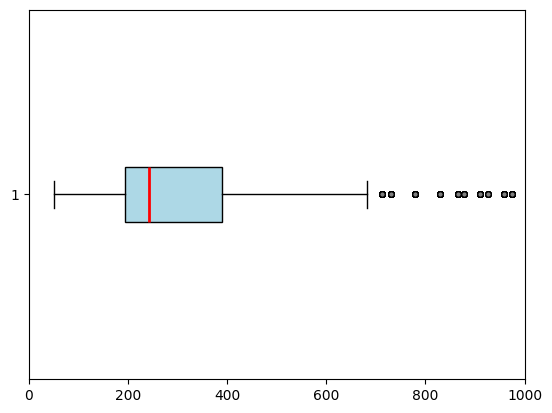

In [ ]:
# Создаем боксплот
plt.boxplot(df['total'],
                 vert=False,
                 patch_artist=True,
                 boxprops=dict(facecolor='lightblue'),
                 medianprops=dict(color='red', linewidth=2),
                 flierprops=dict(marker='o', markersize=4, markerfacecolor='grey'))
plt.xlim(0, 1000)  # оставить видимыми только значения до 200
plt.show()


- Тут на графике явно видно, что большинство чеков лежит в диапазоне до 700р.

- Присутствует множество покупок дороже 700р, что кофейня предлагает продукты в разных ценовых диапазонах.

-----

**Вывод по колонке `total`:**

- Общий чек в кофейнях начинается от 52р.
- Большинство чеков до 700р.
- Медианное значение чеков 234р.
- Данные очень сильно разбросаны, что говорит о наличии в кофейне дорогих продуктов наряду со средними.
- Распределение данных нельзя назвать нормальным.


## Данные о покупателях

### Данные о возрасте

In [ ]:
# описательные статистики для возраста клиентов

df['age'].describe()

,age
count,23062.000000
mean,46.433917
std,15.070853
min,24.000000
25%,33.000000
50%,44.000000
75%,60.000000
max,75.000000


In [ ]:
print(f'Минимальный возраст покупателя: {df['age'].min()}')

print(f'Максимальный возраст покупателя: {df['age'].max()}')

print(f'Средний возраст покупателя: {df['age'].mean().round()}')

print(f'Медианный возраст покупателя: {df['age'].median()}')

Минимальный возраст покупателя: 24
Максимальный возраст покупателя: 75
Средний возраст покупателя: 46.0
Медианный возраст покупателя: 44.0


In [ ]:
df['age'].quantile()

np.float64(44.0)

- Значение 44.0 — это 50-й процентиль (медиана)

- Половина выборки (50%) имеет возраст 44 года или меньше

- Вторая половина выборки (50%) старше 44 лет

In [ ]:
# Выведем стандартное отклонение

df[ ['age'] ].std()

,0
age,15.070853


- **Стандартное отклонение** около 15 лет показывает, что в выборке присутствуют как достаточно молодые, так и относительно пожилые участники.

In [ ]:
# Выведем коэффицент ассиметрии (Skewness)

df[ ['age'] ].skew()

,0
age,0.290215


- Распределение возраста имеет **положительную асимметрию (правостороннюю)**

- Большинство значений сосредоточено в левой части распределения

- В выборке преобладают более молодые респонденты, количество людей старшего возраста постепенно уменьшается


In [ ]:
# Выведем коэффициент эксцесса

df[ ['age'] ].kurtosis()

,0
age,-1.199773


- Распределение имеет плоский пик по сравнению с нормальным распределением

- Возрастные группы представлены достаточно равномерно. Нет явного преобладания какого-либо возрастного диапазона

- Распределение **ближе к равномерному,** чем к нормальному

In [ ]:
# Проверим нормальность распределения
# H0 - выборка соответствует нормальному закону распределения
# H1 - выборка не соответствует нормальному закону распределения

stats.shapiro(df['age'])

/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 23062.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=np.float64(0.9366460913056162), pvalue=np.float64(6.164887130972683e-70))

- Крайне низкое p-value (<< 0.05) позволяет отвергнуть нулевую гипотезу о нормальности распределения

- **Распределение возраста нельзя считать нормальным**

<Axes: xlabel='age', ylabel='Count'>

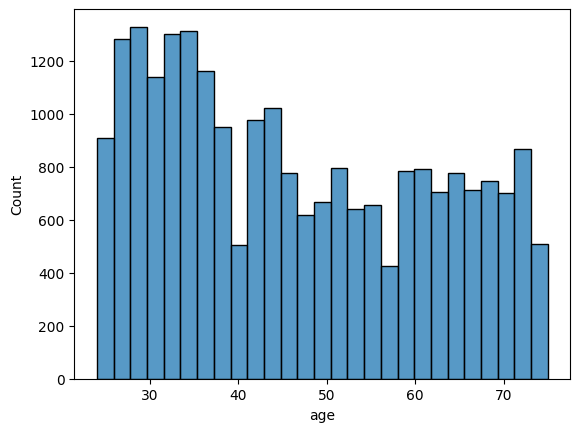

In [ ]:
# Визуализируем полученные данные

import seaborn as sns

sns.histplot(df['age'])  # визуализация

- Видим равномерное, а не нормальное распределение возраста, с концентрацией значений слева, которая говорит о том, что **в датасете больше представителей молодого возраста.**

- Видим также длинный правый хвост - это постеменно уменьшающееся количество людей старше 44 лет.

<Axes: xlabel='age_group', ylabel='Count'>

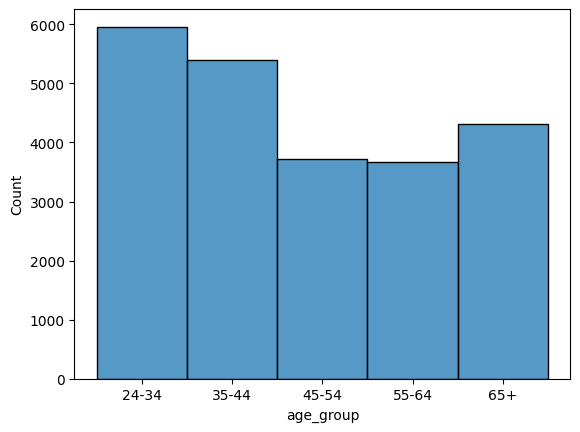

In [ ]:
# Гистограмма распределения по возрастным группам

import seaborn as sns

sns.histplot(df['age_group'])

- По гистограмме возрастных групп также видно, что больше всего посетителей кофейни в возрасте 24-34 и 35-44 лет.

____

**Выводы по колонке `age`**:

- Распределение данных нельзя считать нормальным.
- Разброс данных большой, с длинным правм хвостом, что говорит о том, что в выборке присутствует много молодых людей до 44 лет и меньше пожилых.
- Двумя ведущими возрастными группами являются группы 24-34 и 34-44 года.

**Относительно возраста клиента можно сделать вывод, что это посетитель от 24 до 44 лет.**

### Возраст и продажи

In [ ]:
# Посмотрим среднее общего чека, распределенное по возрастным группам

df.groupby('age_group')['total'].mean()

/tmp/ipython-input-171450509.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('age_group')['total'].mean()


,total
age_group,
24-34,299.906401
35-44,300.633986
45-54,301.130526
55-64,307.585697
65+,294.231024


- В возрастной группе молодых взрослых (24-34 года) средний чек - 299р.

- В группе 34-44 года средний чек 300р.

- Самый высокий средний чек в возрастной группе 55-64 - 306р, хотя эта возрастная группа посещает кофейни почти в два раза реже. Эта группа если уж и приходит в кофейню то тратит побольше.

- Однако, средние траты во всех возрастных группах не сильно отличаются (до 10 рублей), **нет возрастной группы, которая тратит сильно больше.**


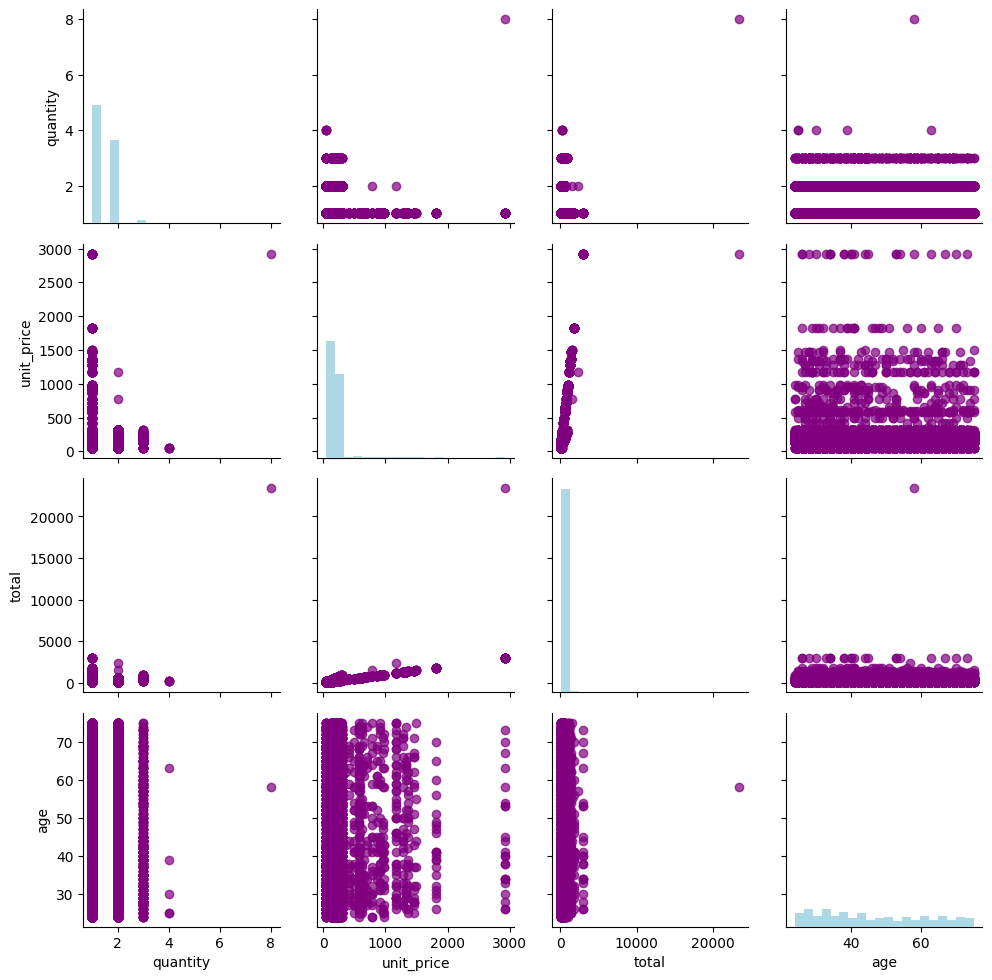

In [ ]:
# Построим сетку парных графиков и посмотрим есть ли какая либо связь возраста с продажами
# H0 - Возраст не оказывает влияния на продажи
# H1 - Возраст клиента влияет на продажи

# Создаем PairGrid (сетку парных графиков) для выбранных колонок
g = sns.PairGrid(df, vars=['quantity', 'unit_price', 'total', 'age'])

# На диагонали строим гистограммы распределения
g.map_diag(plt.hist, bins=20, color='lightblue')

# Вне диагонали строим scatter plot для парных зависимостей
g.map_offdiag(plt.scatter, alpha=0.7, color='purple')

plt.show()

- Возраст (`age`) не проявляет явной зависимости ни с `quantity`, ни с `unit_price`, ни с `total` — точки распределены широко и сгущены по рядам, без явного тренда.

- В целом, наибольшая очевидная связь наблюдается между `unit_price` и `total`, менее выражена между `quantity` и `total`. Такая картина ожидаема, так как общий чек зависит от цены на продукт и количества купленнего.

- **Возраст не влияет на продажи.**

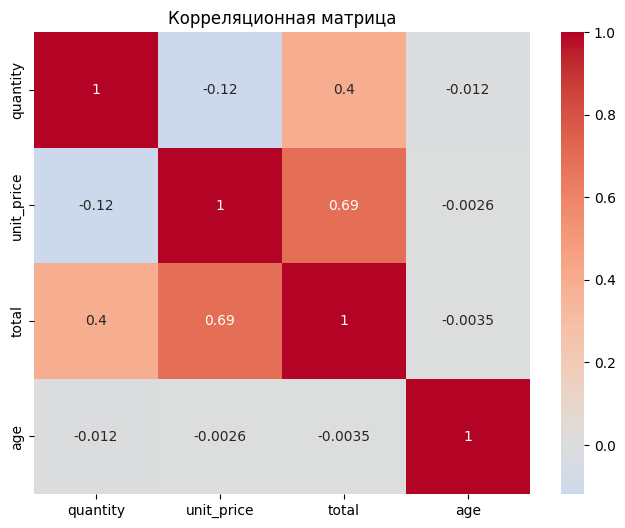

In [ ]:
# Построим матрицу корреляций и убедимся, что возраст не влияет на продажи
# H0 - Возраст не оказывает влияния на продажи
# H1 - Возраст клиента влияет на продажи

# Выбираем числовые колонки
columns = ['quantity', 'unit_price', 'total', 'age']

# Вычисляем корреляционную матрицу
corr_matrix = df[columns].corr()

# Создаем тепловую карту корреляций
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)

plt.title('Корреляционная матрица')
plt.show()

- Между `unit_price` и `total` сильная положительная корреляция 0.69, что логично - с увеличением цены за единицу общая сумма чека растёт.

- Между `quantity` и `total` умеренная положительная корреляция 0.40, т.е. увеличение количества товаров в заказе обычно ведёт к увеличению суммы покупки.

- Корреляции `age` с другими переменными близки к нулю (-0.01 - 0.00), что говорит об отсутствии линейных взаимосвязей между возрастом и продажами.

----

**Выводы по связи `age` и `total`**:

- Средние траты во всех возрастных группах не сильно отличаются (до 10 рублей), нет возрастной группы, которая тратит сильно больше.

- Сетка парных графиков не показывает существенной взаимосвязи колонки `age` ни с `total`, ни c `quantity`, ни с `unit_price`

- Матрица корреляций также не показывает линейных взаимосвязей.



- **Возраст клиетов не влияет на продажи**.

- **Клиенты разных возрастов тратят в кофейне примерно 300+- р.**

### Пол и продажи

In [ ]:
gender_counts = df['gender'].value_counts()

gender_counts

,count
gender,
женский,10023
мужской,7627
не указан,5412


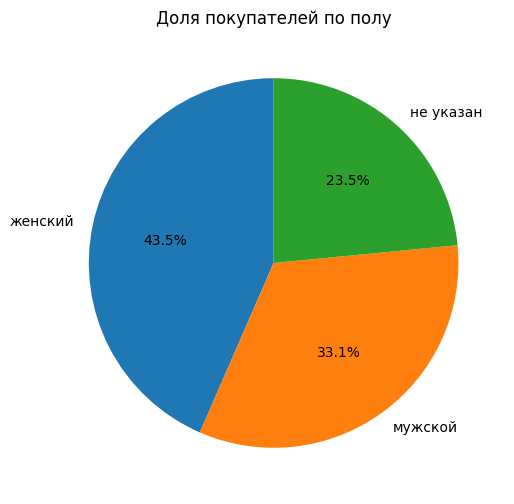

In [ ]:
# Визуализация доли покупателей по полу


plt.figure(figsize=(6,6))
gender_counts.plot.pie(autopct='%1.1f%%', startangle=90)
plt.title('Доля покупателей по полу')
plt.ylabel('')
plt.show()

Во всем датасете женщин больше, чем мужчин среди тех, кто указал пол.

In [ ]:
# Посмотрим кого больше среди посетителей кофейни в возрасте до 44 лет: мужчин или женщин.

age_groups = ['24-34', '35-44']

# Фильтрация по нужным возрастным группам
filtered = df[df['age_group'].isin(age_groups)]

# Подсчёт количества мужчин и женщин среди этих групп
count_by_sex = filtered['gender'].value_counts()

print(count_by_sex)


gender
не указан    4591
женский      3972
мужской      2786
Name: count, dtype: int64


In [ ]:
3972-2786

1186

- Среди посетителей кофейни в возрасте 24-44 года (наш ведущий возраст) больше женщин, чем мужчин на 1186 посетителей.

- Это значительная цифра, которая составляет почти 4 часть всех посетителей, которые указали пол.

- **Такие цифры позволяют сделать вывод, что наш типичный клиент - женщина.**

----

Посмотрим, есть ли разница в общем чеке среди мужчин и женщин:

In [ ]:
# Cоздаем две отдельные выборки две отдельные выборки, содержащие только числовые значения total

men = df[df['gender'] == 'мужской']['total']
women = df[df['gender'] == 'женский']['total']

print(stats.shapiro(men))
print(stats.shapiro(women))

ShapiroResult(statistic=np.float64(0.6530371589295618), pvalue=np.float64(2.65483879944846e-82))
ShapiroResult(statistic=np.float64(0.29460803581954853), pvalue=np.float64(2.975716088886361e-106))


/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 7627.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10023.
  res = hypotest_fun_out(*samples, **kwds)


- Значения 0.653 и 0.295 сильно отклоняются от 1, что указывает на явное нарушение нормальности.

- p-value крайне низкие.

- Данные в обеих выборках не подчиняются нормальному распределению.

In [ ]:
# Применяем критерий Манна-Уитни
scipy.stats.mannwhitneyu(men, women, alternative='two-sided') # для случая непараметрического критерия

MannwhitneyuResult(statistic=np.float64(38268203.5), pvalue=np.float64(0.8917843246965865))

**Интерпретация результата критерия Манна-Уитни:**

1. **Значение p-value (0.8917):**
p-value > 0.05 (стандартный уровень значимости), что означает:

- Нет статистически значимых различий между сравниваемыми выборками.

- Нулевая гипотеза (H₀) о том, что выборки взяты из одного распределения, не отвергается.

2. **U-статистика (38268203.5):**
Абсолютное значение U-статистики само по себе не интерпретируется, но в контексте p-value оно подтверждает:

- Выборки очень похожи по своему распределению.

- Любые наблюдаемые различия между группами можно считать случайными.



----

Выводы по связи `gender`и `total`:

- Среди посетителей кофеен женщин больше, чем мужчин.
- Среди посетителей до 44 лет **наш типичный клиент - женщина**.
- Нет статистически значимых различий между общим чеком мужчин и женщин

## Информация о продуктах

In [ ]:
# Описательные статистики для цены 1 продукта

df['unit_price'].describe()

,unit_price
count,23062.000000
mean,215.425564
std,150.364064
min,52.000000
25%,162.500000
50%,195.000000
75%,243.750000
max,2925.000000


In [ ]:
print(f'Минимальная стоимость продукта в кофейне: {df['unit_price'].min()}')

print(f'Максимальная стоимость продукта в кофейне {df['unit_price'].max()}')

print(f'Средняя стоимость продукта в кофейне: {df['unit_price'].mean().round()}')

print(f'Медианная стоимость 1 продукта в кофейне: {df['unit_price'].median()}')

Минимальная стоимость продукта в кофейне: 52.0
Максимальная стоимость продукта в кофейне 2925.0
Средняя стоимость продукта в кофейне: 215.0
Медианная стоимость 1 продукта в кофейне: 195.0


- Минимальная, медианная и максимальная цена за продукт сильно различаются, что говорит о том, что в кофейнях есть продукты с высокими ценами (выбросами).

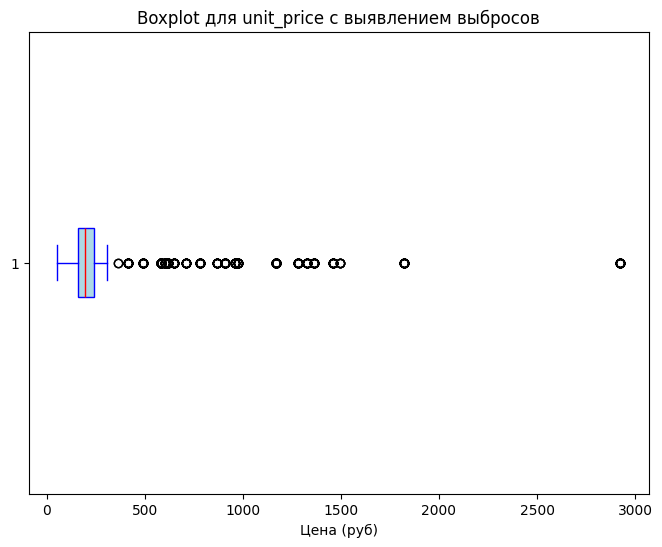

In [ ]:
plt.figure(figsize=(8,6))
plt.boxplot(df['unit_price'], vert=False, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            whiskerprops=dict(color='blue'),
            capprops=dict(color='blue'),
            medianprops=dict(color='red'))
plt.title('Boxplot для unit_price с выявлением выбросов')
plt.xlabel('Цена (руб)')
plt.show()

Выбросов действительно много, это говорит о том, что в кофейне присутствует продукты, которые сильно дороже "ходовой цены". Такие продукты стоят от 400 до 3000 рублей за штуку.

In [ ]:
# Посмотрим какие продукты продаются чаще всего

sales_per_product = df.groupby('product_name')['quantity'].sum().sort_values(ascending=False)

print(sales_per_product)

product_name
Latte                          743
Earl Grey Rg                   742
Brazilian Sm                   738
Morning Sunrise Chai Rg        738
Our Old Time Diner Blend Sm    728
                              ... 
Espresso Roast                  16
Earl Grey                       15
Chili Mayan                     14
Peppermint                      14
Spicy Eye Opener Chai           13
Name: quantity, Length: 80, dtype: int64


**Эти продукты продаются в кофейнях чаще всего**: `Latte, Earl Grey Rg, Brazilian Sm, Morning Sunrise Chai Rg, Our Old Time Diner Blend Sm`

**Эти продукты продаются реже всего и на продажи не влияют**: `Espresso Roast, Earl Grey, Chili Mayan, Peppermint, Spicy Eye Opener Chai`

In [ ]:
# Группируем по продукту и суммируем количество продаж
sales_per_product = df.groupby('product_name')['quantity'].sum()

# Находим продукт с максимальными продажами
best_selling_product = sales_per_product.idxmax()
best_selling_count = sales_per_product.max()

print(f"Лучший продаваемый продукт: {best_selling_product} с {best_selling_count} продажами")

Лучший продаваемый продукт: Latte с 743 продажами


**Наиболее продаваемый продукт в кофейнях - Latte.**

Итак, наш клиент уже превратился в женщину от 24 до 44, покупающую Латте.

In [ ]:
# Проверим

# Фильтрация по продукту "Латте"
latte_customers = df[df['product_name'] == 'Latte']

# Подсчёт количества мужчин и женщин среди покупателей латте
count_by_gender = latte_customers['gender'].value_counts()

print(count_by_gender)

gender
женский      201
мужской      152
не указан    125
Name: count, dtype: int64


Действительно женщин, покупающих Латте больше, чем мужчин.

---

### Продукты и город

store_city          Москва  Санкт-Петербург
product_category                           
Bakery                2288             1127
Branded                 50               25
Coffee                6158             3119
Coffee beans           163               43
Drinking Chocolate    1154              677
Flavours               598              135
Loose Tea              111               41
Packaged Chocolate      43               18
Tea                   4801             2511


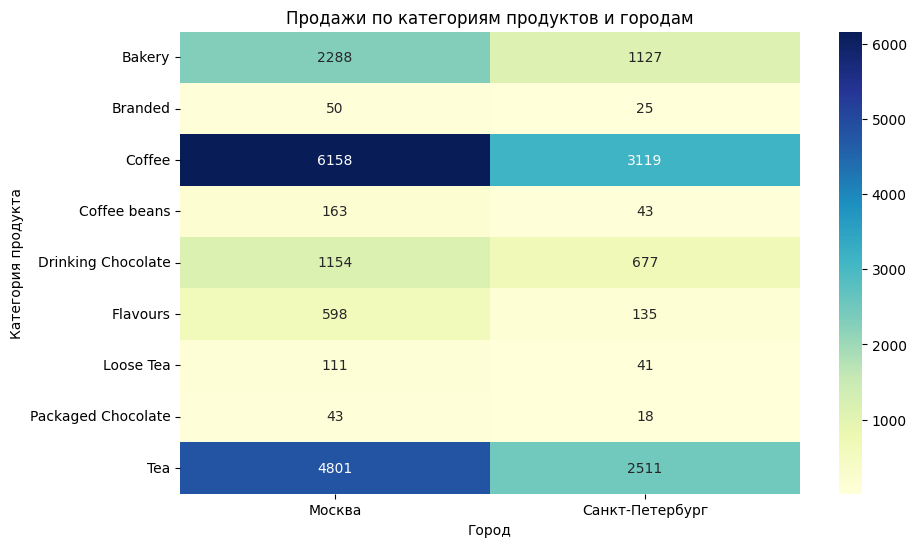

In [ ]:
 #crosstab: сравним число продаж по категориям продуктов и городам

WF=pd.crosstab(df['product_category'], df['store_city']); WF
print(WF)

# Можно построить heatmap для crosstab
plt.figure(figsize=(10,6))
sns.heatmap(WF, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Продажи по категориям продуктов и городам')
plt.xlabel('Город')
plt.ylabel('Категория продукта')
plt.show()

- Нужно аккурано относится к этим данным, потому что данных по Москве в принципе в 2 раза больше, чем по Санкт-Петербургу, т.к. у нас есть только 1 точка продаж из этого города.

- Поэтому логично, что продажи в Москве обгоняют продажи в Санкт-Петербурге в 2 раза по всем категориям. Если бы данные по двум городам присутствовали в одинаковом объеме мы могли бы точнее сказать, какие категории в каких городах продаются лучше всего.

- Самые популярные категории в обоих городах – Coffee и Tea, на третьем месте Bakery. Можно сказать, что эти три категории лучше всего продаются во всех кофейнях.



In [ ]:
# H0 - связь между факторами продукт и город отсутствует
# H1 - связь между факторами продукт и город есть

chi2, prob, f, expected = scipy.stats.chi2_contingency(WF)
output = "test Statistics: {}\ndegrees of freedom: {}\np-value: {}\n"

print(output.format( chi2, f, prob))

test Statistics: 105.64777477512956
degrees of freedom: 8
p-value: 2.9792448245292772e-19



**Статистика теста (χ² = 105.65):**

  - Значение хи-квадрат показывает, насколько сильно наблюдаемые частоты в кросс-таблице отличаются от ожидаемых при условии независимости переменных.

  - Чем выше значение, тем сильнее связь между переменными. В вашем случае значение **105.65 указывает на очень сильное расхождение между реальными данными и гипотезой о независимости**.

**p-value = 2.98e-19:**

  - Это вероятность получить такие или более крайние результаты при условии, что переменные независимы.

  - p-value крайне малое - отвергаем нулевую гипотезу о независимости переменных.

  - **Вывод: между переменными есть статистически значимая связь.**

  - Переменные в кросс-таблице тесно связаны. Выбор категорий товаров зависит от города.

----


**Выводы по разделу:**
- Самый популярный продукт - Латте.
- Среди покупателей Латте женщин также больше, чем мужчин.
- **Наш типичный клиент - женщина 24-44 года, покупающая Латте.**
- Самые популярные продукты в обоих городах Coffie, Tea, Bakery
- Между категориями и городом есть статистически значимая связь. Выбор категорий товаров зависит от города. Но к данным нужно относится крайне акуратно из-за их несбалансированности.



## Информация о торговых точках

In [ ]:
df['store_city'].describe()

,store_city
count,23062
unique,2
top,Москва
freq,15366


In [ ]:
# Группировка по ID точки продаж

outlet_analysis = df.groupby('sales_outlet_id').agg(total_sales=('total', 'sum'),
                                                     total_quantity=('quantity', 'sum'),
                                                     avg_check=('total', 'mean')).reset_index()

outlet_analysis

,sales_outlet_id,total_sales,total_quantity,avg_check
0,3,2256064.2,10812,293.147635
1,5,2498141.1,12123,305.695191
2,8,2174433.3,10248,302.256505


Тут явно видно, что **ID 5** точка продаж выигрывает и по числу проданных позиций и по общим продажам и по среднему чеку.


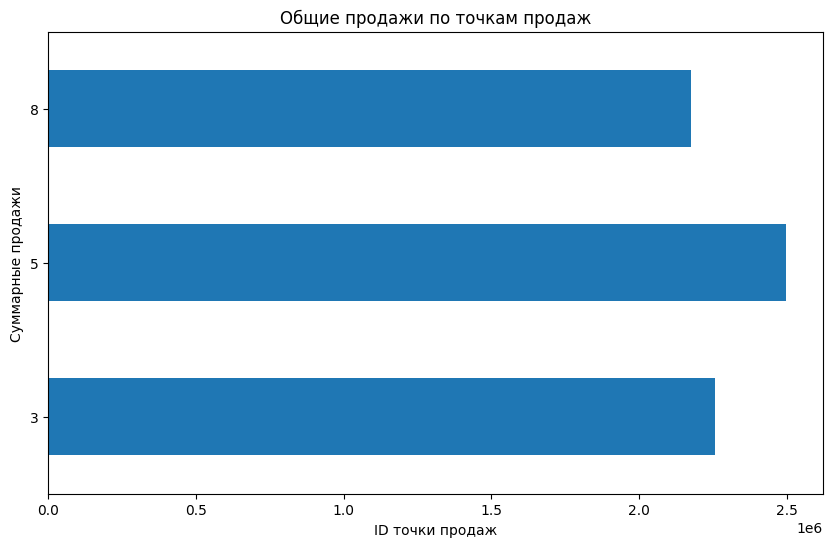

In [ ]:
# Визуализируем

# Группируем по точке продаж и суммируем продажи
total_sales_by_outlet = df.groupby('sales_outlet_id')['total'].sum()

# Строим гистограмму (бар-чарт) суммарных продаж по точкам
total_sales_by_outlet.plot(kind='barh', figsize=(10,6), title='Общие продажи по точкам продаж')
plt.xlabel('ID точки продаж')
plt.ylabel('Суммарные продажи')
plt.show()

In [ ]:
# Посмотрим, где находится точка 5 (заодно проверим другие в этом же коде)

# Фильтрация по id точки продаж 5
point_5 = df[df['sales_outlet_id'] == 5]

# Получение города (если таких записей несколько, можно взять первый)
city = point_5['store_city'].iloc[0]

print(f"Точка с id=5 находится в городе: {city}")

Точка с id=5 находится в городе: Москва


**Из трех представленных в датасете точек (3,5,8) наиболее успешна точка ID 5, которая находится в Москве.**

На втором месте идет точка с ID 3 (Санкт-Петербург).

На третьем месте идет точка с ID 8 (Москва).


In [ ]:
# Наиболее продаваемые продукты на точке, проверим не Latte ли

top_outlet_products = (df[df['sales_outlet_id'] == 5].groupby('product_name')['quantity'].sum().sort_values(ascending=False))

best_product = top_outlet_products.idxmax()
best_quantity = top_outlet_products.max()

print(f"Лучший продаваемый продукт на точке с id=5: {best_product} с количеством продаж {best_quantity}")

Лучший продаваемый продукт на точке с id=5: Latte с количеством продаж 290


In [ ]:
# Выведем 5 наиболее популярных продуктов на этой точке

top_outlet_products.head(5)

,quantity
product_name,
Latte,290
Morning Sunrise Chai Rg,278
Columbian Medium Roast Rg,272
English Breakfast Rg,272
Lemon Grass Rg,269


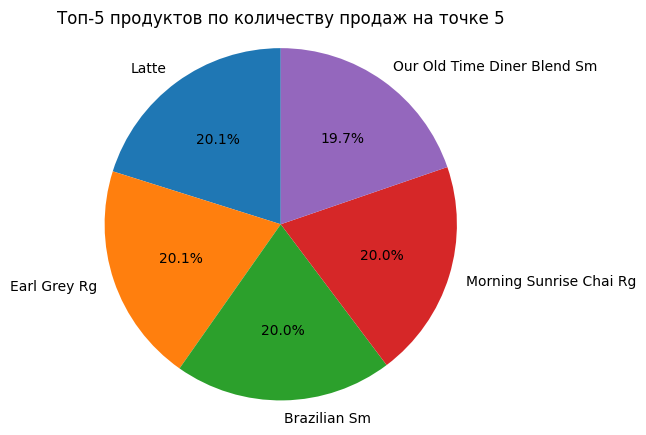

In [ ]:
# Визуализируем

top5 = df.groupby('product_name')['quantity'].sum().nlargest(5).reset_index()

# Пример данных
product_names = top5['product_name']
sales_values = top5['quantity']

# Построение круговой диаграммы
plt.figure(figsize=(5, 5))
plt.pie(sales_values, labels=product_names, autopct='%.1f%%', startangle=90)
plt.title('Топ-5 продуктов по количеству продаж на точке 5')
plt.axis('equal')  # Чтобы круг выглядел как круг
plt.show()

- Латте отрывается немного от всех остальных продуктов, проданных на точке.

- В относительных показателях 5 продуктов поровну делят между собой Топ-5.

- Все эти 5 продуктов можно считать успешными на точке.

In [ ]:
# Посмотрим какие продукты идут в конце по продажам

top_outlet_products.tail(5)

,quantity
product_name,
Earl Grey,4
Lemon Grass,4
Columbian Medium Roast,3
Guatemalan Sustainably Grown,3
Morning Sunrise Chai,1


**Выводы по точкам продаж:**

- **Самая успешная точка по продажам - ID 5, которая находится в Москве**. На втором месте идет ID 3 в Санкт-Петербурге.

- Точка №5 успешна и по общему чеку и по количеству проданных товаров.

- На этой точке также лидирует продукт Латте.

- 5 наиболее успешных продуктов делят Топ-5 поровну: Latte, Morning Sunrise Chai R, Columbian Medium, Roast Rg	, English Breakfast R, Lemon Grass Rg

- Эти продукты не вносят вклада в продажи на точке: Earl Grey, Lemon Grass	Columbian Medium Roast,Guatemalan Sustainably Grown,
Morning Sunrise Chai


# Выводы по анализу


- Больше всего кофейню посещают клиенты в возрасте 24 до 44 лет.

- Типичный клиент кофейни - женщина 24-44 лет с любимым продуктом Латте.

- Возраст не влияет на количество продаж. Клиенты разных возрастов тратят в кофейне примерно 300+- р.

- Пол также не влияет на продажи. Между мужчинами и женщинами нет существенной разницы в общем чеке.

- Среди продуктов кофейни присутствуют как очень дешевые (52 р), так и дорогие (более 500 р), но чаще всего покупаются продукты в диапазоне 215+- р.

- Средний чек в кофейнях около 300р

- Наиболее продаваяемая категория - Coffie

- Эти продукты продаются в кофейнях чаще всего: `Latte, Earl Grey Rg, Brazilian Sm`. На эти продукты можно сделать ставку, открывая новые кофейни.

- Эти продукты продаются реже всего и на продажи не влияют: `Espresso Roast, Earl Grey, Chili Mayan, Peppermint, Spicy Eye Opener Chai`. Эти продукты можно убрать из продаж как неэффективные.

- Из трех представленных в датасете точек (3,5,8) наиболее успешна по продажам точка ID 5, которая находится в Москве.

- В этой точке также наиболее успешным является продукт Латте.

- Наиболее успешные продукты на точке 5:`Latte, Morning Sunrise Chai Rg, Columbian Medium Roast Rg, English Breakfast Rg, Lemon Grass Rg,`

- Наименее успешные продукты на точке 5: `Earl Grey, Lemon Grass, Columbian Medium Roast, Guatemalan Sustainably Grown, Morning Sunrise Chai`

- При анализе категорий покупок по городам выявлена статистически значимая связь. Возможно, выбор категории продукта зависит от города. Однако к данным относится нужно акуратно, т.к. данных по одной категории городов (Москва) в два раза больше, чем по второй.

- Среди всех городов наиболее популярные категории: Coffie, Tea, Bakery





# Рекомендации для заказчика

- В своем рекламе и позиционировании ориентироваться на женщин 24–44 лет. Сделать акценты в рекламе или в акциях, которые направлены на эту возрастную группу.

- Позиционировать Латте как "фирменный" продукт, сделать с ним специальные рецепты, сезонные акции, чтобы привлечь клиентов возвращаться за этим напитком в новом качестве.

- Сосредоточиться на развитии продуктов с максимальным оборотом: Latte, Earl Grey Rg, Brazilian Sm, т.к. они обеспечивают основные продажи.

- Оставить в ассортименте коффеен наиболее востребованные категории: Coffee, Tea, Bakery. В обоих городах они продаются лучше всего.

- Избавиться от неэффективных продуктов (Espresso Roast, Earl Grey, Chili Mayan, Peppermint, Spicy Eye Opener Chai).

- В ценах ориентироваться на чек около 215-300р, т.к. именно эти чек комфортны для большинства посетителей.

- Проводить акции, учитывая средний чек в 300р, например "обед за 300р" и делать допродажи уже к этой акции.

- Для открытия новых точек рассмотреть Москву, т.к. самая успешная точка (ID 5) находится там.

- Собрать больше данных по точке в Санкт-Петербурге, чтобы сделать более адекватные выводы и проанализировать продажи там.

